# **Gaia DR3 Variable Stars:** Data Audit and Exploratory Analysis

## Imports and Configuration

In [29]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from gaia_variable_stars.config import SOURCE_FILE, PHOTOMETRY_FILE, CLEAN_FILE, FEATURE_FILE, FIGURES_ROOT, CLASSES, MIN_POINTS
from gaia_variable_stars.dataset import clean, label, normalize

FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

In [30]:
sources = pd.read_csv(SOURCE_FILE)
photometry = normalize(pd.read_csv(PHOTOMETRY_FILE, dtype={"transit_id": "string"}))

## Data Overview

### Schema and Source Integrity

In [31]:
source_cols = [
    "source_id", "class_name", "gaia_period", "gaia_period_origin",
    "ecl_lon", "ecl_lat", "bp_rp_color", "g_mean_magnitude", "n_g_epochs"
]

photometry_cols = [
    "source_id", "transit_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error", "variability_flag_g_reject"
]

assert set(source_cols).issubset(sources.columns), f"Missing source fields: {set(source_cols) - set(sources)}"
assert set(photometry_cols).issubset(photometry.columns), f"Missing photometry fields: {set(photometry_cols) - set(photometry)}"
assert sources["source_id"].is_unique and sources["class_name"].isin(CLASSES).all()
assert photometry["source_id"].isin(sources["source_id"]).all()

labeled = label(sources, photometry)

print("Sources:", len(sources))
print("Photometry:", len(photometry))

Sources: 2000
Photometry: 90126


In [32]:
display(sources["class_name"].value_counts().reindex(CLASSES, fill_value=0).to_frame("stars"))
display(sources.head(3))

,stars
class_name,
RR Lyrae,500
Cepheid,500
Eclipsing Binary,500
Long-Period Variable,500


,source_id,random_index,ra,dec,ecl_lon,ecl_lat,g_mean_magnitude,bp_mean_magnitude,rp_mean_magnitude,bp_rp_color,gaia_pf,gaia_p1_o,class_name,gaia_p2_o,gaia_frequency,gaia_period,gaia_period_origin,n_g_epochs
0,245251978451433728,1520826064,56.420114,46.682834,65.001881,26.115460,18.876387,19.333345,18.299236,1.034109,NaN,0.337184,RR Lyrae,NaN,NaN,0.337184,p1_o,37
1,5712669411241837184,1286622709,117.543461,-20.286212,124.754685,-40.459960,17.915445,18.395552,17.215742,1.179810,0.626575,NaN,RR Lyrae,NaN,NaN,0.626575,pf,45
2,5862160287770085632,343164423,198.333702,-63.766373,229.098839,-50.145385,20.633400,22.233725,19.275316,2.958408,0.637236,NaN,RR Lyrae,NaN,NaN,0.637236,pf,24


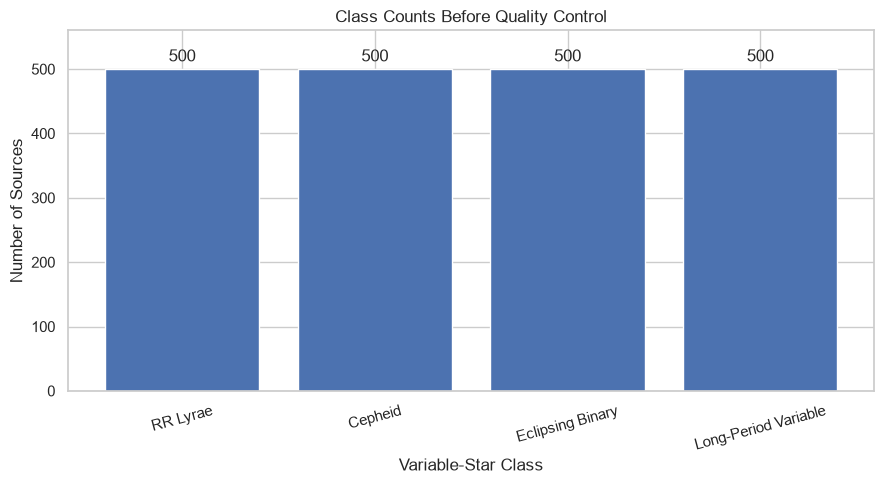

In [33]:
class_counts = sources["class_name"].value_counts().reindex(CLASSES, fill_value=0)

figure, axis = plt.subplots(figsize=(9, 5))

bars = axis.bar(CLASSES, class_counts)
axis.bar_label(bars, padding=3)

axis.set(
    ylim=(0, class_counts.max() * 1.12),
    xlabel="Variable-Star Class",
    ylabel="Number of Sources",
    title="Class Counts Before Quality Control"
)

axis.tick_params(axis="x", rotation=15)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "class_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### Observation Quality Check

In [34]:
checks = labeled.copy()

for col in ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]:
    checks[col] = pd.to_numeric(checks[col], errors="coerce")

flag = checks["variability_flag_g_reject"].astype("string").str.strip().str.lower()

checks["missing_id"] = checks["transit_id"].isna()
checks["duplicate_id"] = checks["transit_id"].notna() & checks.duplicated(["source_id", "transit_id"], keep=False)
checks["duplicate_time"] = checks["g_transit_time"].notna() & checks.duplicated(["source_id", "g_transit_time"], keep=False)
checks["invalid_time"] = ~np.isfinite(checks["g_transit_time"])
checks["invalid_magnitude"] = ~np.isfinite(checks["g_transit_mag"])
checks["invalid_flux"] = checks["g_transit_flux"].notna() & (~np.isfinite(checks["g_transit_flux"]) | checks["g_transit_flux"].le(0))
checks["missing_flux"] = checks["g_transit_flux"].isna()
checks["invalid_error"] = ~np.isfinite(checks["g_transit_flux_error"]) | checks["g_transit_flux_error"].le(0)
checks["unknown_flag"] = ~flag.isin(["true", "false", "1", "0", "1.0", "0.0", "t", "f"])
checks["rejected"] = flag.isin(["true", "1", "1.0", "t"])

In [35]:
issue_cols = [
    "missing_id", "duplicate_id", "duplicate_time", "invalid_time", "invalid_magnitude",
    "invalid_flux", "missing_flux", "invalid_error", "unknown_flag", "rejected"
]

issues = checks.groupby(["class_name", "source_id"])[issue_cols].any()
issues = issues.groupby("class_name").sum().reindex(CLASSES, fill_value=0)

print("Sources with at least one affected observation:")
display(issues.astype(int))

Sources with at least one affected observation:


,missing_id,duplicate_id,duplicate_time,invalid_time,invalid_magnitude,invalid_flux,missing_flux,invalid_error,unknown_flag,rejected
class_name,,,,,,,,,,
RR Lyrae,0,0,0,175,175,0,175,175,0,333
Cepheid,0,0,0,350,350,0,350,350,0,444
Eclipsing Binary,0,0,0,257,257,0,257,257,0,399
Long-Period Variable,0,0,0,316,316,0,316,316,0,358


In [36]:
cleaned = clean(labeled)
retained = labeled.index.isin(cleaned.index)

print("Clean Observations:", len(cleaned))
print("Removed Observations:", len(labeled) - len(cleaned))

Clean Observations: 85243
Removed Observations: 4883


In [37]:
counts = pd.DataFrame({
    "raw": labeled.groupby("class_name").size(),
    "clean": cleaned.groupby("class_name").size()
})

display(counts.reindex(CLASSES).fillna(0).astype(int))

,raw,clean
class_name,,
RR Lyrae,20800,20010
Cepheid,23439,21672
Eclipsing Binary,22884,21685
Long-Period Variable,23003,21876


### Cleaning Consistency

In [38]:
saved = pd.read_csv(CLEAN_FILE, dtype={"transit_id": "string"})

cols = [
    col for col in [
        "source_id", "transit_id", "g_transit_time", "g_transit_mag",
        "g_transit_flux", "g_transit_flux_error"
    ] if col in saved and col in cleaned
]

sort_cols = [col for col in ["source_id", "g_transit_time", "transit_id"] if col in cols]

left = saved[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)
right = cleaned[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)

pd.testing.assert_frame_equal(left, right, check_dtype=False, rtol=1e-8, atol=1e-8)

print("Saved Cleaning Matches:", True)
print("Saved Observations:", len(saved))

Saved Cleaning Matches: True
Saved Observations: 85243


In [39]:
counts = cleaned.groupby("source_id").size().reindex(sources["source_id"], fill_value=0)
changed = sources["n_g_epochs"].ne(counts.to_numpy()).sum()

print("Changed Epoch Counts:", int(changed))

Changed Epoch Counts: 0


### Missingness and Period Origins

In [40]:
observed_cols = ["gaia_period", "ecl_lat", "g_mean_magnitude", "bp_rp_color"]
obs_cols = ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]

print("Missing source fields (%):")
display(sources.groupby("class_name")[observed_cols].agg(lambda x: x.isna().mean() * 100).reindex(CLASSES).round(2))

print("Missing observation fields (%):")
display(labeled.groupby("class_name")[obs_cols].agg(lambda x: x.isna().mean() * 100).reindex(CLASSES).round(2))

print("Gaia reference period origin:")
display(pd.crosstab(sources["class_name"], sources["gaia_period_origin"]).reindex(CLASSES, fill_value=0))

Missing source fields (%):


,gaia_period,ecl_lat,g_mean_magnitude,bp_rp_color
class_name,,,,
RR Lyrae,0.0,0.0,0.0,7.4
Cepheid,0.0,0.0,0.0,0.0
Eclipsing Binary,0.0,0.0,0.0,0.8
Long-Period Variable,0.0,0.0,0.0,0.0


Missing observation fields (%):


,g_transit_time,g_transit_mag,g_transit_flux,g_transit_flux_error
class_name,,,,
RR Lyrae,1.31,1.31,1.31,1.31
Cepheid,2.52,2.52,2.52,2.52
Eclipsing Binary,1.78,1.78,1.78,1.78
Long-Period Variable,2.14,2.14,2.14,2.14


Gaia reference period origin:


gaia_period_origin,frequency,p1_o,pf
class_name,,,
RR Lyrae,0,188,312
Cepheid,0,193,307
Eclipsing Binary,500,0,0
Long-Period Variable,500,0,0


In [41]:
period_summary = sources.groupby("class_name")["gaia_period"].agg(
    stars="size", min="min", q1=lambda x: x.quantile(0.25),
    median="median", q3=lambda x: x.quantile(0.75), max="max"
).reindex(CLASSES)

print("Gaia reference period (days) by class:")
display(period_summary.round(3))

Gaia reference period (days) by class:


,stars,min,q1,median,q3,max
class_name,,,,,,
RR Lyrae,500,0.212,0.321,0.483,0.588,0.891
Cepheid,500,0.213,1.924,3.150,5.490,108.654
Eclipsing Binary,500,0.200,0.313,0.418,1.065,190.638
Long-Period Variable,500,35.116,102.866,249.127,427.166,963.112


## Photometric Precision

In [42]:
quality = checks
quality["retained"] = retained

valid_error = (
    np.isfinite(quality["g_transit_flux"]) & quality["g_transit_flux"].gt(0)
    & np.isfinite(quality["g_transit_flux_error"]) & quality["g_transit_flux_error"].gt(0)
)
quality["magnitude_error"] = (1.0857 * quality["g_transit_flux_error"] / quality["g_transit_flux"]).where(valid_error)

reject_state = labeled["variability_flag_g_reject"].astype("string").str.lower().fillna("missing")
display(pd.crosstab(
    [labeled["class_name"], reject_state], retained,
    rownames=["class", "variability_flag_g_reject"], colnames=["retained"]
).loc[CLASSES])

display(
    quality.groupby(["class_name", "retained"])["magnitude_error"]
    .agg(n_valid="count", median_mag_error="median").round(4).loc[CLASSES]
)

retained                                        False  True 
class                variability_flag_g_reject              
RR Lyrae             false                          0  20010
                     true                         790      0
Cepheid              false                          0  21672
                     true                        1767      0
Eclipsing Binary     false                          0  21685
                     true                        1199      0
Long-Period Variable false                          0  21876
                     true                        1127      0

n_valid  median_mag_error
class_name           retained                           
RR Lyrae             False         518            0.0411
                     True        20010            0.0069
Cepheid              False        1176            0.0039
                     True        21672            0.0024
Eclipsing Binary     False         792            0.0254
                     True        21685            0.0079
Long-Period Variable False         634            0.0039
                     True        21876            0.0025

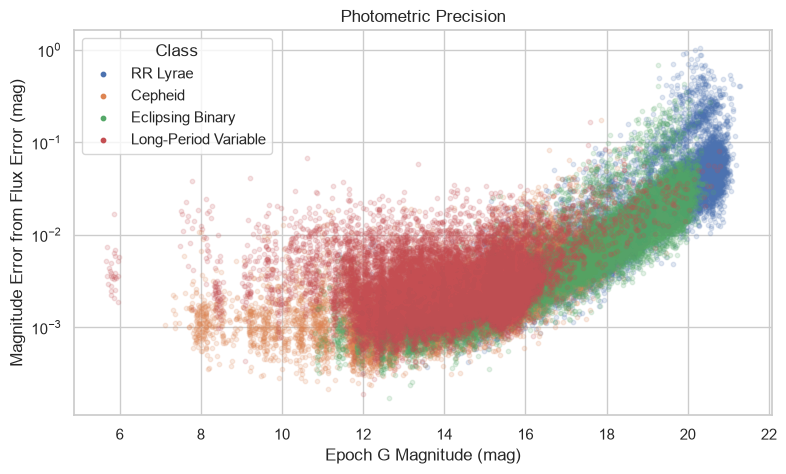

In [43]:
figure, axis = plt.subplots(figsize=(9, 5))

precision = quality.loc[quality["retained"] & quality["magnitude_error"].gt(0)]

for name in CLASSES:
    part = precision.loc[precision["class_name"].eq(name)]
    axis.scatter(part["g_transit_mag"], part["magnitude_error"], s=10, alpha=0.16, label=name, rasterized=True)

legend = axis.legend(title="Class")
for handle in legend.legend_handles:
    handle.set_alpha(1)

axis.set(yscale="log", xlabel="Epoch G Magnitude (mag)", ylabel="Magnitude Error from Flux Error (mag)", title="Photometric Precision")

figure.savefig(FIGURES_ROOT / "photometric_precision.png", dpi=160, bbox_inches="tight")
plt.show()

## Star-Level Measurements

In [44]:
obs_cols = [
    "source_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error"
]

observations = cleaned[obs_cols].sort_values(["source_id", "g_transit_time"]).copy()

flux = pd.to_numeric(observations["g_transit_flux"], errors="coerce")
error = pd.to_numeric(observations["g_transit_flux_error"], errors="coerce")
valid_error = np.isfinite(flux) & flux.gt(0) & np.isfinite(error) & error.gt(0)

observations["magnitude_error"] = (1.0857 * error / flux).where(valid_error)
observations["time_gap"] = observations.groupby("source_id")["g_transit_time"].diff()
observations["short_gap"] = observations["time_gap"].between(0, 1, inclusive="neither")
observations["long_gap"] = observations["time_gap"].gt(30)
observations["new_group"] = observations["time_gap"].gt(1)

In [45]:
star_stats = observations.groupby("source_id").agg(
    n_epochs=("g_transit_time", "size"),
    time_span=("g_transit_time", lambda x: x.max() - x.min()),
    median_gap=("time_gap", "median"),
    positive_gaps=("time_gap", lambda x: x.gt(0).sum()),
    short_gaps=("short_gap", "sum"),
    long_gaps=("long_gap", "sum"),
    observing_groups=("new_group", lambda x: int(x.sum()) + 1),
    magnitude_mean=("g_transit_mag", "mean"),
    magnitude_std=("g_transit_mag", "std"),
    magnitude_skew=("g_transit_mag", "skew"),
    magnitude_kurt=("g_transit_mag", pd.Series.kurt),
    magnitude_mad=("g_transit_mag", lambda x: (x - x.median()).abs().median()),
    amplitude=("g_transit_mag", lambda x: x.quantile(0.95) - x.quantile(0.05)),
    median_error=("magnitude_error", "median"),
    valid_errors=("magnitude_error", "count")
).reset_index()

In [46]:
stars = sources.merge(star_stats, on="source_id", how="left", validate="one_to_one")

stars["n_epochs"] = stars["n_epochs"].fillna(0).astype(int)
stars["valid_errors"] = stars["valid_errors"].fillna(0).astype(int)
stars["abs_latitude"] = stars["ecl_lat"].abs()
stars["usable"] = stars["n_epochs"].ge(MIN_POINTS)
stars["short_gap_fraction"] = stars["short_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["long_gap_fraction"] = stars["long_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["amplitude_ratio"] = stars["amplitude"] / stars["median_error"].replace(0, np.nan)
stars["scatter_ratio"] = stars["magnitude_std"] / stars["median_error"].replace(0, np.nan)

print("Star Dataset:", len(stars))

display(
    stars.groupby("class_name")[
        ["n_epochs", "time_span", "median_gap", "amplitude", "median_error", "amplitude_ratio"]
    ].median().reindex(CLASSES).round(3)
)

Star Dataset: 2000


,n_epochs,time_span,median_gap,amplitude,median_error,amplitude_ratio
class_name,,,,,,
RR Lyrae,37.0,933.938,0.375,0.465,0.008,61.988
Cepheid,39.0,979.944,26.996,0.403,0.002,162.329
Eclipsing Binary,40.0,959.394,7.842,0.278,0.009,28.977
Long-Period Variable,42.0,959.343,17.467,0.318,0.002,134.554


,n,median,q1,q3
class_name,,,,
RR Lyrae,500,37.0,30.0,44.25
Cepheid,500,39.0,35.0,47.00
Eclipsing Binary,500,40.0,33.0,54.00
Long-Period Variable,500,42.0,36.0,50.00


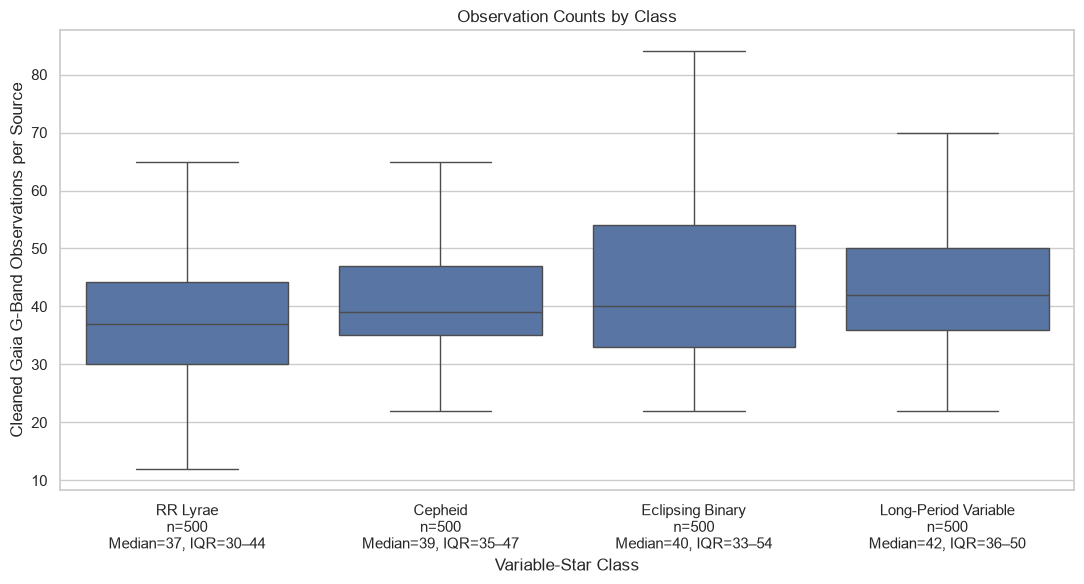

In [47]:
observation_summary = (
    stars.groupby("class_name")["n_epochs"]
    .agg(
        n="size",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reindex(CLASSES)
)

display(observation_summary.round(2))

figure, axis = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=stars,
    x="class_name",
    y="n_epochs",
    order=CLASSES,
    showfliers=False,
    ax=axis
)

axis.set_xticks(
    range(len(CLASSES)),
    [
        f"{name}\nn={observation_summary.loc[name, 'n']:.0f}\n"
        f"Median={observation_summary.loc[name, 'median']:.0f}, "
        f"IQR={observation_summary.loc[name, 'q1']:.0f}–"
        f"{observation_summary.loc[name, 'q3']:.0f}"
        for name in CLASSES
    ]
)

axis.set(
    xlabel="Variable-Star Class",
    ylabel="Cleaned Gaia G-Band Observations per Source",
    title="Observation Counts by Class"
)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "observation_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### Measurement Bias and Cadence

In [48]:
rr_lyrae = stars.loc[stars["class_name"].eq("RR Lyrae")].copy()
rr_lyrae["missing_color"] = rr_lyrae["bp_rp_color"].isna()

missing_color = rr_lyrae.groupby("missing_color")[["g_mean_magnitude", "n_epochs", "median_error", "amplitude"]].median()
missing_color.insert(0, "n", rr_lyrae["missing_color"].value_counts())
display(missing_color.round(3))

display(stars.groupby("class_name")[["short_gap_fraction", "long_gap_fraction", "observing_groups", "scatter_ratio"]].median().reindex(CLASSES).round(3))

print("Stars with amplitude / median error <= 3:", int(stars["amplitude_ratio"].le(3).sum()))
print("Stars with std / median error > 10:", int(stars["scatter_ratio"].gt(10).sum()))

,n,g_mean_magnitude,n_epochs,median_error,amplitude
missing_color,,,,,
False,463,17.985,37.0,0.008,0.476
True,37,20.083,32.0,0.046,0.407


,short_gap_fraction,long_gap_fraction,observing_groups,scatter_ratio
class_name,,,,
RR Lyrae,0.513,0.303,18.0,20.889
Cepheid,0.361,0.402,26.0,57.447
Eclipsing Binary,0.483,0.344,20.0,10.841
Long-Period Variable,0.435,0.333,24.0,44.772


Stars with amplitude / median error <= 3: 0
Stars with std / median error > 10: 1569


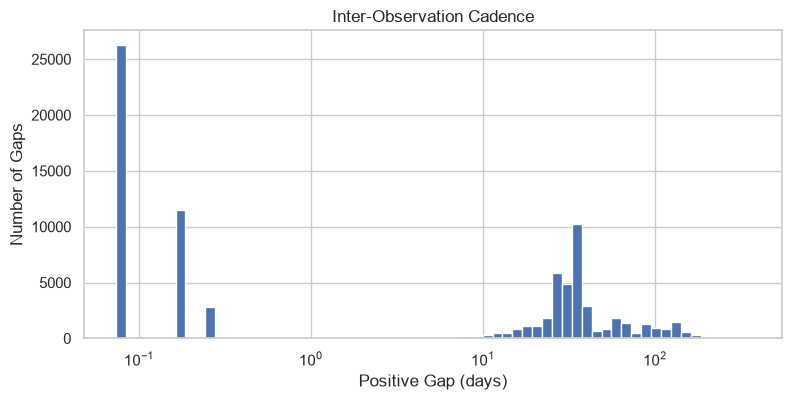

In [49]:
gaps = observations.loc[observations["time_gap"].gt(0), "time_gap"]

figure, axis = plt.subplots(figsize=(9, 4))
if len(gaps):
    axis.hist(gaps, bins=np.geomspace(gaps.min(), gaps.max() * 1.00001, 65))
    axis.set_xscale("log")
axis.set(xlabel="Positive Gap (days)", ylabel="Number of Gaps", title="Inter-Observation Cadence")

figure.savefig(FIGURES_ROOT / "02_observation_gaps.png", dpi=160, bbox_inches="tight")
plt.show()

## Sky Coverage and Sample Selection

In [50]:
stars["latitude_bin"] = pd.cut(stars["abs_latitude"], [0, 15, 30, 45, 60, 75, 90], include_lowest=True)

display(pd.crosstab(stars["class_name"], stars["latitude_bin"]).reindex(CLASSES, fill_value=0))
display(stars.groupby(["class_name", "latitude_bin"], observed=True)[["n_epochs", "median_gap", "short_gap_fraction"]].median().round(2))

latitude_bin,"(-0.001, 15.0]","(15.0, 30.0]","(30.0, 45.0]","(45.0, 60.0]","(60.0, 75.0]","(75.0, 90.0]"
class_name,,,,,,
RR Lyrae,152,106,140,64,22,16
Cepheid,46,19,39,66,25,305
Eclipsing Binary,129,127,0,0,52,192
Long-Period Variable,99,96,53,24,21,207


n_epochs  median_gap  short_gap_fraction
class_name           latitude_bin                                            
Cepheid              (-0.001, 15.0]      30.0       11.46                0.48
                     (15.0, 30.0]        42.0        0.21                0.54
                     (30.0, 45.0]        52.0        0.18                0.59
                     (45.0, 60.0]        53.5       13.82                0.46
                     (60.0, 75.0]        45.0       24.99                0.37
                     (75.0, 90.0]        37.0       28.17                0.32
Eclipsing Binary     (-0.001, 15.0]      44.0        0.18                0.61
                     (15.0, 30.0]        30.0       17.59                0.43
                     (60.0, 75.0]        58.0        0.25                0.54
                     (75.0, 90.0]        41.0       28.49                0.34
Long-Period Variable (-0.001, 15.0]      33.0        0.18                0.56
                     (15.0, 30.0]        47.0        0.18                0.57
                     (30.0, 45.0]        52.0        0.18                0.57
                     (45.0, 60.0]        59.0        0.18                0.52
                     (60.0, 75.0]        47.0       25.75                0.40
                     (75.0, 90.0]        39.0       27.67                0.33
RR Lyrae             (-0.001, 15.0]      35.0        0.21                0.54
                     (15.0, 30.0]        32.0        3.50                0.50
                     (30.0, 45.0]        40.0        0.25                0.52
                     (45.0, 60.0]        49.5       15.86                0.45
                     (60.0, 75.0]        40.5       27.67                0.36
                     (75.0, 90.0]        35.0       28.93                0.32

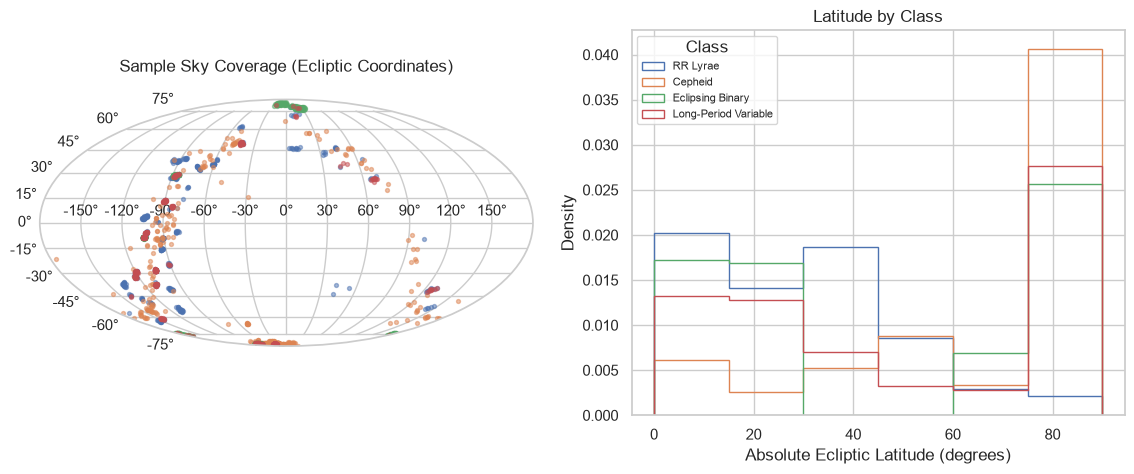

In [51]:
figure = plt.figure(figsize=(14, 5))

sky_axis = figure.add_subplot(121, projection="mollweide")
latitude_axis = figure.add_subplot(122)

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name)].dropna(subset=["ecl_lon", "ecl_lat"])
    longitude = (group["ecl_lon"] + 180) % 360 - 180
    sky_axis.scatter(np.radians(longitude), np.radians(group["ecl_lat"]), s=8, alpha=0.5, label=name)
    latitude_axis.hist(group["abs_latitude"], bins=[0, 15, 30, 45, 60, 75, 90], density=True, histtype="step", label=name)

sky_axis.set_title("Sample Sky Coverage (Ecliptic Coordinates)", pad=20)
sky_axis.grid(True)

latitude_axis.set(xlabel="Absolute Ecliptic Latitude (degrees)", ylabel="Density", title="Latitude by Class")
latitude_axis.legend(title="Class", fontsize=8)

figure.savefig(FIGURES_ROOT / "sky_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## Light Curves and Photometric Structure

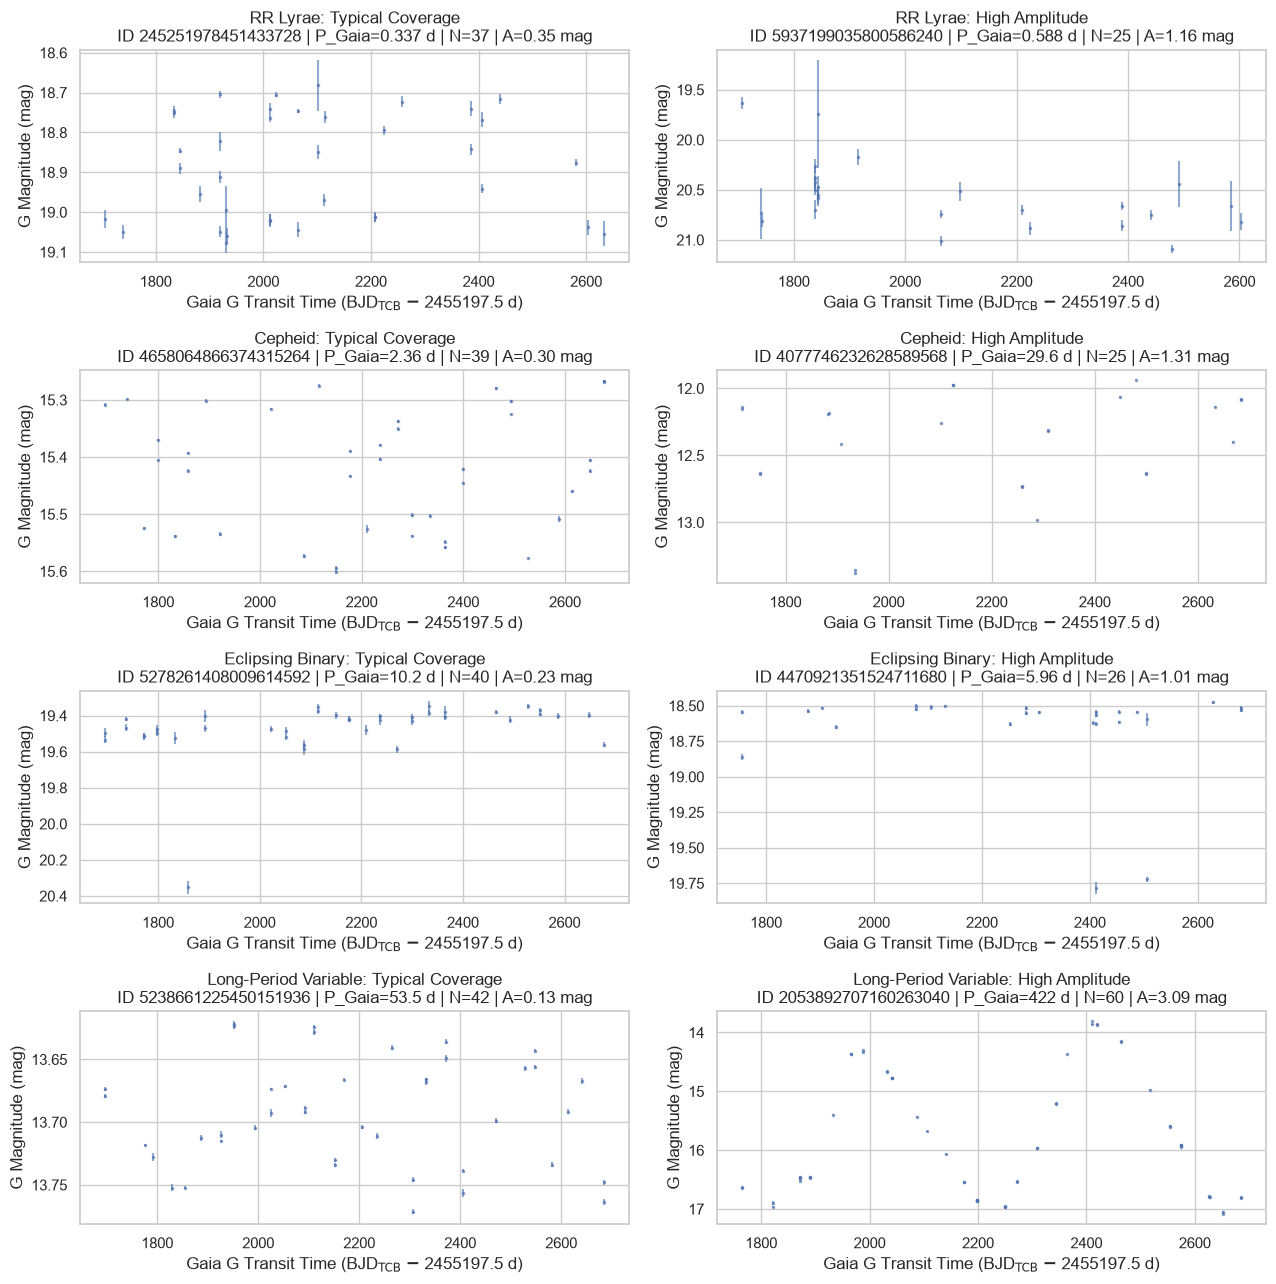

In [52]:
figure, axes = plt.subplots(4, 2, figsize=(13, 13))

for row, name in enumerate(CLASSES):
    group = stars.loc[stars["class_name"].eq(name) & stars["usable"]]
    typical = group.iloc[(group["n_epochs"] - group["n_epochs"].median()).abs().argmin()]
    high = group.loc[group["amplitude"].idxmax()]

    for axis, (label_name, star) in zip(axes[row], [("Typical Coverage", typical), ("High Amplitude", high)]):
        curve = observations.loc[observations["source_id"].eq(star["source_id"])]
        axis.errorbar(curve["g_transit_time"], curve["g_transit_mag"], yerr=curve["magnitude_error"], fmt=".", ms=3, alpha=0.6)
        axis.invert_yaxis()
        axis.set(
            title=f"{name}: {label_name}\nID {int(star['source_id'])} | P_Gaia={star['gaia_period']:.3g} d | N={star['n_epochs']} | A={star['amplitude']:.2f} mag",
            xlabel=r"Gaia G Transit Time (BJD$_{\mathrm{TCB}}$ $-$ 2455197.5 d)", ylabel="G Magnitude (mag)"
        )

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "light_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## Color and Amplitude Overlap Between Classes

In [53]:
overlap = []

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name), ["bp_rp_color", "amplitude"]].dropna()

    for comparison in CLASSES:
        if name == comparison:
            continue
        reference = stars.loc[stars["class_name"].eq(comparison), ["bp_rp_color", "amplitude"]].dropna()
        inside = group.ge(reference.quantile(0.05)).all(axis=1) & group.le(reference.quantile(0.95)).all(axis=1)
        overlap.append({"class": name, "reference_class": comparison, "stars": len(group), "inside_reference_5_95_box_pct": 100 * inside.mean()})

display(pd.DataFrame(overlap).round(2))

,class,reference_class,stars,inside_reference_5_95_box_pct
0,RR Lyrae,Cepheid,463,77.75
1,RR Lyrae,Eclipsing Binary,463,52.92
2,RR Lyrae,Long-Period Variable,463,10.80
3,Cepheid,RR Lyrae,500,63.60
4,Cepheid,Eclipsing Binary,500,61.40
5,Cepheid,Long-Period Variable,500,16.80
6,Eclipsing Binary,RR Lyrae,496,50.81
7,Eclipsing Binary,Cepheid,496,73.39
8,Eclipsing Binary,Long-Period Variable,496,1.61
9,Long-Period Variable,RR Lyrae,500,7.40


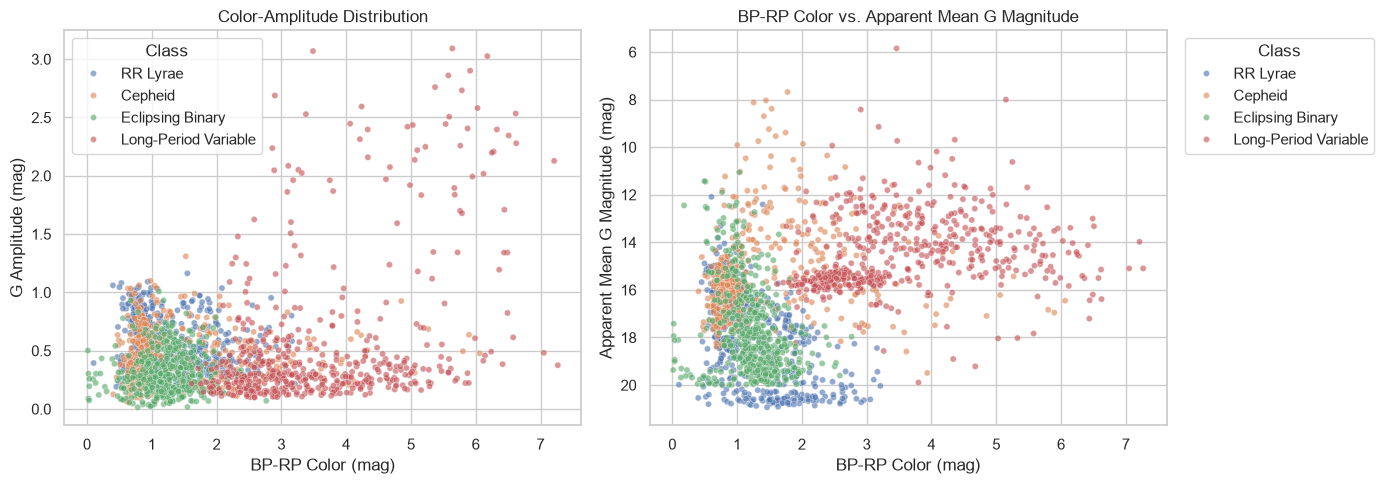

In [54]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=stars, x="bp_rp_color", y="amplitude", hue="class_name", hue_order=CLASSES, alpha=0.6, s=20, ax=axes[0])
axes[0].set(xlabel="BP-RP Color (mag)", ylabel="G Amplitude (mag)", title="Color-Amplitude Distribution")
axes[0].get_legend().set_title("Class")

sns.scatterplot(data=stars, x="bp_rp_color", y="g_mean_magnitude", hue="class_name", hue_order=CLASSES, alpha=0.6, s=20, ax=axes[1])
axes[1].invert_yaxis()
axes[1].set(xlabel="BP-RP Color (mag)", ylabel="Apparent Mean G Magnitude (mag)", title="BP-RP Color vs. Apparent Mean G Magnitude")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.02, 1), title="Class")

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "color_amplitude_magnitude.png", dpi=160, bbox_inches="tight")
plt.show()

## Final Data Audit

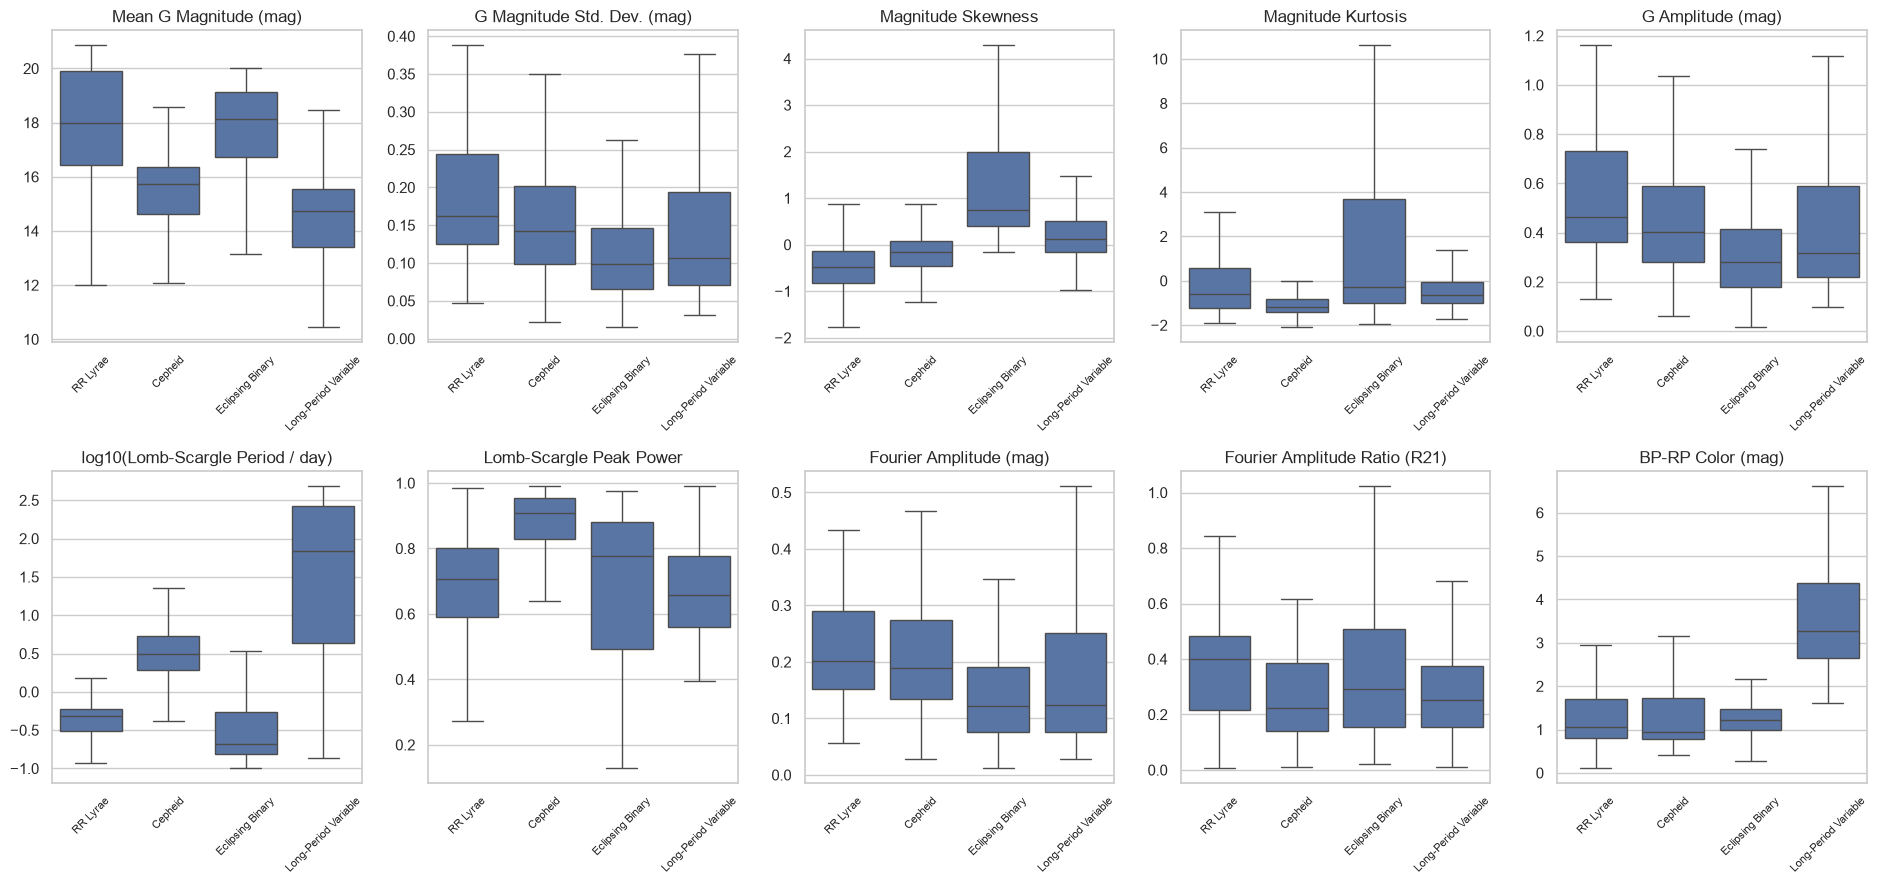

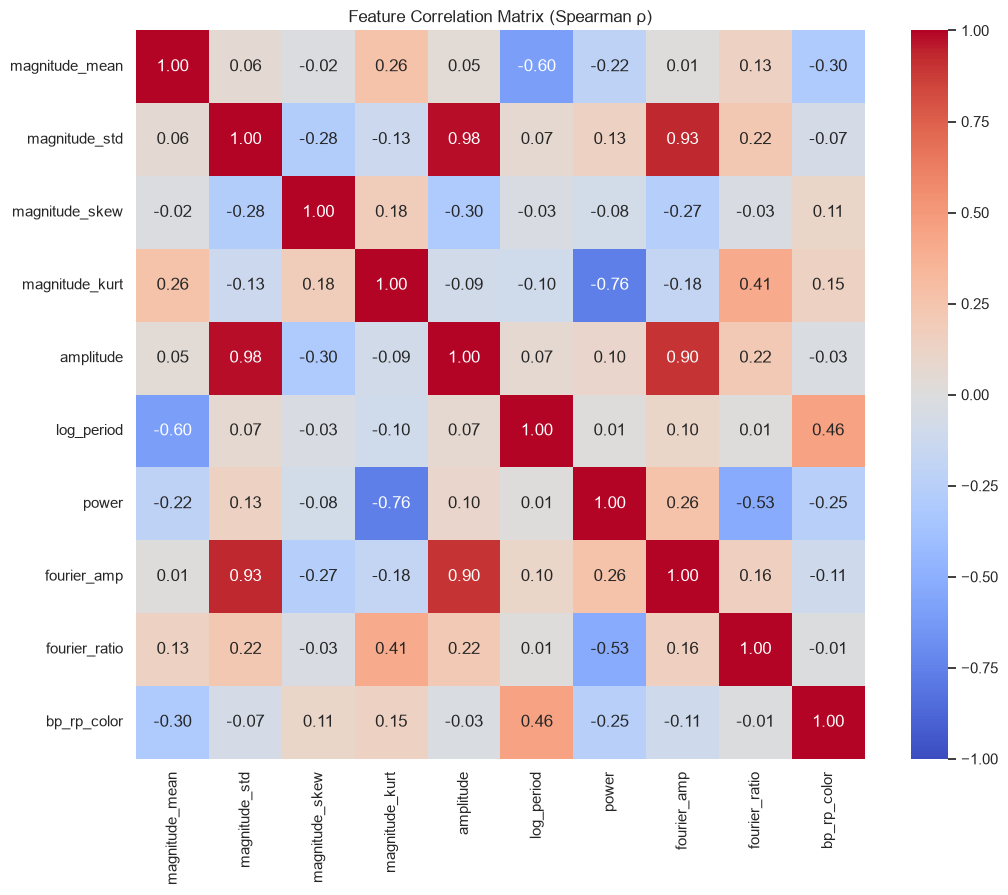

,magnitude_std,amplitude,fourier_amp
magnitude_std,1.000,0.979,0.933
amplitude,0.979,1.000,0.904
fourier_amp,0.933,0.904,1.000


In [55]:
fe_path = FEATURE_FILE.with_name("gaia_features_fe.csv")

if fe_path.exists():
    features = pd.read_csv(fe_path)

    feature_labels = {
        "magnitude_mean": "Mean G Magnitude (mag)",
        "magnitude_std": "G Magnitude Std. Dev. (mag)",
        "magnitude_skew": "Magnitude Skewness",
        "magnitude_kurt": "Magnitude Kurtosis",
        "amplitude": "G Amplitude (mag)",
        "log_period": "log10(Lomb-Scargle Period / day)",
        "power": "Lomb-Scargle Peak Power",
        "fourier_amp": "Fourier Amplitude (mag)",
        "fourier_ratio": "Fourier Amplitude Ratio (R21)",
        "bp_rp_color": "BP-RP Color (mag)",
    }
    feature_cols = list(feature_labels)

    figure, axes = plt.subplots(2, 5, figsize=(19, 9))

    for axis, (col, title) in zip(axes.flat, feature_labels.items()):
        sns.boxplot(data=features, x="class_name", y=col, order=CLASSES, showfliers=False, ax=axis)
        axis.set(title=title, xlabel="", ylabel="")
        axis.tick_params(axis="x", rotation=45, labelsize=8)

    figure.tight_layout()
    figure.savefig(FIGURES_ROOT / "feature_distributions.png", dpi=160, bbox_inches="tight")
    plt.show()

    corr = features[feature_cols].corr(method="spearman")

    figure, axis = plt.subplots(figsize=(11, 9))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=axis)
    axis.set_title("Feature Correlation Matrix (Spearman ρ)")

    figure.tight_layout()
    figure.savefig(FIGURES_ROOT / "feature_correlation.png", dpi=160, bbox_inches="tight")
    plt.show()

    redundant = ["magnitude_std", "amplitude", "fourier_amp"]
    display(corr.loc[redundant, redundant].round(3))

else:
    print("Feature plots require the outputs from notebook 02.")

In [56]:
flow = pd.DataFrame({
    "selected": sources["class_name"].value_counts(),
    "photometry_retrieved": sources.loc[sources["source_id"].isin(photometry["source_id"]), "class_name"].value_counts(),
    "clean_photometry": sources.loc[sources["source_id"].isin(cleaned["source_id"]), "class_name"].value_counts(),
    "min_epochs_pass": stars.loc[stars["usable"], "class_name"].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)

flow["lost_not_retrieved"] = flow["selected"] - flow["photometry_retrieved"]
flow["lost_no_clean_photometry"] = flow["photometry_retrieved"] - flow["clean_photometry"]
flow["lost_below_min_epochs"] = flow["clean_photometry"] - flow["min_epochs_pass"]

if fe_path.exists():
    modeled = pd.read_csv(fe_path, usecols=["source_id", "class_name"])
    flow["final_modeling_cohort"] = modeled["class_name"].value_counts().reindex(CLASSES, fill_value=0)
    flow["lost_feature_qc"] = flow["min_epochs_pass"] - flow["final_modeling_cohort"]

flow.loc["Total"] = flow.sum()
display(flow)

audit = pd.Series({
    "Initial Sources": len(sources),
    "Raw Observations": len(photometry),
    "Clean Observations": len(cleaned),
    "Sources Passing Minimum Epoch Count": int(stars["usable"].sum()),
    "Sources With Valid BP-RP Color": int(stars["bp_rp_color"].notna().sum()),
})

if fe_path.exists():
    audit["Final Modeling Sources"] = len(modeled)

display(audit.to_frame("count"))

,selected,photometry_retrieved,clean_photometry,min_epochs_pass,lost_not_retrieved,lost_no_clean_photometry,lost_below_min_epochs,final_modeling_cohort,lost_feature_qc
class_name,,,,,,,,,
RR Lyrae,500,500,500,478,0,0,22,478,0
Cepheid,500,500,500,500,0,0,0,500,0
Eclipsing Binary,500,500,500,500,0,0,0,500,0
Long-Period Variable,500,500,500,500,0,0,0,500,0
Total,2000,2000,2000,1978,0,0,22,1978,0


,count
Initial Sources,2000
Raw Observations,90126
Clean Observations,85243
Sources Passing Minimum Epoch Count,1978
Sources With Valid BP-RP Color,1959
Final Modeling Sources,1978
